# 3. Results: clustering comparison and required CVRP evaluation

Run [classical](classical_capacity_constrained_clustering.ipynb) and
[quantum](quantum_capacity_constrained_clustering.ipynb) first.
Clustering samples are read from saved evidence, not rerun.
This is the only notebook that constructs routing references or evaluates tours.
CVRP evaluation is required for Track A by section 9.2 of the brief.

## What the numbers mean

- **Feasible:** every customer served once, no overloaded vehicle.
- **Model gap:** clustering cost versus the exact clustering optimum.
- **CVRP gap:** exact tours of the measured groups versus the full CVRP optimum.
- **Feasibility rate:** feasible shots / all shots.
- **Hit probability:** feasible shots within the chosen gap / all shots.

Example: 5 legal shots and 2 reference hits out of 100 shots mean
**5% feasibility and 2% hit probability**, not 40%.
Missing gaps mean undefined, not zero error.

In [1]:
from pathlib import Path
import json
import sys
from time import perf_counter
import numpy as np
import pandas as pd
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "track_a" / "inputs" / "seeds_s.json").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from track_a.common.instances import OUTPUT_PATH, Instance, ensure_instances, feasible, validate
from track_a.common.analysis import fingerprint, save
from track_a.common.models import ENCODING

instances = ensure_instances()
print(f"Processing all {len(instances)} demand vectors:", [i.id for i in instances])
output = OUTPUT_PATH
shots = 256
seed = 0

import csv
from dataclasses import asdict
from itertools import combinations, permutations
from math import prod
from track_a.common.classical import partitions
from track_a.common.models import canonical, decode, objective
from track_a.common.report import write_report

GAP_TOLERANCE_PERCENT = 0.1

Processing all 10 demand vectors: ['s-0', 's-1', 's-2', 's-3', 's-4', 's-5', 's-6', 's-7', 's-8', 's-9']


## Required CVRP evaluation (Track A, section 9.2)

This is **classical evaluation only**, not part of quantum optimization.
Compute the exact full-CVRP reference, including depot legs, and cross-check
it with CPLEX. Then route measured feasible groups without changing their members.
The model gap and CVRP gap answer different questions.

The functions below try every grouping and visit order on these small S
instances. Vehicle relabelings and reversed tours count only once.
Save missing references once; subsequent results runs reuse them.
Customer coordinates remain internal and are not displayed.

In [2]:
class Routing:
    def __init__(self, instance: Instance):
        self.coordinates = instance.coordinates
        self.depot = instance.depot
        self.distances = instance.distances
        self.to_depot = np.linalg.norm(np.asarray(instance.coordinates) - instance.depot, axis=1)
        self.tours = {(): (0.0, ())}

    def length(self, order: tuple[int, ...]) -> float:
        if not order:
            return 0.0
        return float(self.to_depot[order[0]] + self.to_depot[order[-1]] +
                     sum(self.distances[a, b] for a, b in zip(order, order[1:])))

    def tour(self, group: tuple[int, ...]) -> tuple[float, tuple[int, ...]]:
        group = tuple(sorted(group))
        if group not in self.tours:
            self.tours[group] = min((self.length(order), order) for order in permutations(group))
        return self.tours[group]

    def evaluate(self, instance: Instance, labels: tuple[int, ...]) -> dict:
        if (instance.coordinates != self.coordinates or instance.depot != self.depot
                or not feasible(instance, labels)):
            raise ValueError("Invalid fixed-group routing request")
        tours = []
        for vehicle in range(instance.vehicles):
            group = tuple(i for i, v in enumerate(labels) if v == vehicle)
            cost, order = self.tour(group)
            tours.append({"vehicle": vehicle, "customers": list(order),
                          "route": ["depot", *order, "depot"], "cost": cost,
                          "load": sum(instance.demands[i] for i in group)})
        return {"cost": sum(t["cost"] for t in tours), "tours": tours}

In [3]:
def cplex_crosscheck(instance: Instance, reference: dict, time_limit: float = 30.0) -> dict:
    from docplex.mp.model import Model
    from docplex.mp.utils import DOcplexException

    start = perf_counter()
    routing = Routing(instance)
    groups = [group for size in range(1, instance.n + 1)
              for group in combinations(range(instance.n), size)
              if sum(instance.demands[i] for i in group) <= instance.capacity]
    costs = {
        "clustering": [sum(instance.distances[i, j] for i, j in combinations(g, 2)) for g in groups],
        "cvrp": [routing.tour(g)[0] for g in groups],
    }
    outputs = {}
    for name, values in costs.items():
        try:
            with Model(name=f"track_a_{name}") as model:
                selected = model.binary_var_list(len(groups))
                for customer in range(instance.n):
                    model.add_constraint(model.sum(selected[j] for j, group in enumerate(groups)
                                                   if customer in group) == 1)
                model.add_constraint(model.sum(selected) <= instance.vehicles)
                model.minimize(model.sum(float(cost) * selected[j] for j, cost in enumerate(values)))
                model.parameters.timelimit = time_limit
                model.parameters.threads = 1
                model.parameters.randomseed = 0
                solution = model.solve(log_output=False)
                outputs[name] = {"status": model.solve_details.status, "cost": None}
                if solution is not None:
                    value = solution.objective_value
                    if abs(value - reference[name]["cost"]) > 1e-6:
                        raise AssertionError("CPLEX and exhaustive reference disagree")
                    outputs[name].update(cost=value, agrees=True)
        except DOcplexException as error:
            outputs[name] = {"status": "solver_error", "error": str(error)}
    return {"settings": {"time_limit_seconds": time_limit, "threads": 1, "seed": 0},
            "seconds": perf_counter() - start, **outputs}

In [4]:
def exact_references(instance: Instance) -> dict:
    start = perf_counter()
    routing = Routing(instance)
    candidates = [labels for labels in partitions(instance.n, instance.vehicles)
                  if feasible(instance, labels)]
    if not candidates:
        raise ValueError("No feasible grouping")
    costs = {
        "clustering": [objective(instance, labels) for labels in candidates],
        "cvrp": [routing.evaluate(instance, labels)["cost"] for labels in candidates],
    }
    result = {"status": "proven_optimum", "algorithm": "exhaustive-partitions-and-tours",
              "settings": {"maximum_customers": 4, "vehicle_labels_quotiented": True,
                           "equality_tolerance": 1e-8},
              "feasible_partitions": len(candidates)}
    winners = {}
    for name, values in costs.items():
        best = min(values)
        winners[name] = [labels for labels, cost in zip(candidates, values)
                         if abs(cost - best) <= 1e-8]
        result[name] = {"cost": best, "labels": candidates[values.index(best)],
                        "status": "proven_optimum"}
    result["clustering"]["distinct_optima"] = len(winners["clustering"])
    result["cvrp"]["optimal_partitions"] = len(winners["cvrp"])

    def tour_count(group):
        best, _ = routing.tour(group)
        return len({min(order, order[::-1]) for order in permutations(group)
                    if abs(routing.length(order) - best) <= 1e-8})

    result["cvrp"]["distinct_optima_modulo_reversal"] = sum(
        prod(tour_count(tuple(i for i, v in enumerate(labels) if v == vehicle))
             for vehicle in range(instance.vehicles))
        for labels in winners["cvrp"]
    )
    result["seconds"] = perf_counter() - start
    result["cplex_crosscheck"] = cplex_crosscheck(instance, result)
    return result

In [5]:
def evaluation_references(instances, output: Path) -> None:
    """Add missing full-CVRP references only when preparing results."""
    for instance in instances:
        path = output / "references" / f"{instance.id}.json"
        reference = json.loads(path.read_text())
        if reference["instance_hash"] != fingerprint(asdict(instance)):
            raise ValueError(f"Classical reference does not match {instance.id}")
        if "cvrp" in reference:
            continue
        complete = exact_references(instance)
        if not np.isclose(complete["clustering"]["cost"], reference["clustering"]["cost"]):
            raise AssertionError("Evaluation and clustering references disagree")
        save(path, {**complete, "instance_hash": reference["instance_hash"]})

In [6]:
evaluation_references(instances, output)

## 1. Compute percentage gaps

$$\mathrm{gap}=100(C-C^*)/C^*.$$
Keep negative gaps. Against a zero reference, only an equal zero cost has
gap zero; otherwise the percentage is undefined.

In [7]:
def gap(cost: float, reference: float) -> float | None:
    if reference == 0:
        return 0.0 if cost == 0 else None
    return 100 * (cost - reference) / reference

## 2. Evaluate raw shots, without repair

Route each distinct feasible grouping exactly, keeping its shot count.
Hit thresholds are **0.1%, 1%, 5%**; all raw shots stay in the denominator.
Best model and CVRP gaps may come from different groupings.
No feasible shots means undefined gaps.

In [8]:
def metrics(instance: Instance, counts: dict[str, int], reference: dict,
            routing: Routing) -> tuple[dict, list[dict]]:
    if any(type(count) is not int or count <= 0 for count in counts.values()):
        raise ValueError("Raw counts must be positive integers")
    total = sum(counts.values())
    feasible_count = 0
    evaluations: dict[tuple[int, ...], dict] = {}
    hits = {f"{name}_hit_probability_{threshold:g}pct": 0
            for name in ("model", "cvrp") for threshold in (0.1, 1.0, 5.0)}
    routing_seconds = 0.0
    for bitstring, count in counts.items():
        labels = decode(instance, bitstring)
        if labels is None:
            continue
        feasible_count += count
        if labels not in evaluations:
            start = perf_counter()
            routed = routing.evaluate(instance, labels)
            routing_seconds += perf_counter() - start
            value = objective(instance, labels)
            evaluations[labels] = {
                "labels": list(labels), "model_cost": value, "route_cost": routed["cost"],
                "model_gap": gap(value, reference["clustering"]["cost"]),
                "cvrp_gap": gap(routed["cost"], reference["cvrp"]["cost"]),
                "tours": routed["tours"], "shots": 0,
            }
        item = evaluations[labels]
        item["shots"] += count
        for name in ("model", "cvrp"):
            for threshold in (0.1, 1.0, 5.0):
                if item[f"{name}_gap"] is not None and item[f"{name}_gap"] <= threshold:
                    hits[f"{name}_hit_probability_{threshold:g}pct"] += count
    best_model = min(evaluations.values(), key=lambda e: e["model_cost"], default=None)
    best_route = min(evaluations.values(), key=lambda e: e["route_cost"], default=None)
    return {
        "actual_shots": total, "feasible_shots": feasible_count,
        "feasibility_rate": feasible_count / total if total else None,
        "best_model_gap": best_model["model_gap"] if best_model else None,
        "best_cvrp_gap": best_route["cvrp_gap"] if best_route else None,
        "best_model_labels": best_model["labels"] if best_model else None,
        "best_cvrp_labels": best_route["labels"] if best_route else None,
        "routing_seconds": routing_seconds,
        **{key: value / total if total else None for key, value in hits.items()},
    }, list(evaluations.values())

## 3. Reuse exact tours

Cache by customer coordinates and depot. Routing evaluates fixed groups;
it never reassigns customers or feeds back into optimization.

In [9]:
_ROUTING: dict[tuple, Routing] = {}

def _routing_for(instance: Instance) -> Routing:
    key = instance.coordinates, instance.depot
    if key not in _ROUTING:
        _ROUTING[key] = Routing(instance)
    return _ROUTING[key]

## 4. Validate evidence and export

Check encoding, instance/reference hashes and shot budgets before joining
results. Reuse cached evaluations only when the saved run hash matches.
Write one CSV row per **(instance, method, seed)**. Preserve failed statuses.

In [10]:
def summarize(output: Path) -> list[dict]:
    """Read saved evidence only: never invoke an optimizer or emulator."""
    rows = []
    for path in sorted((output / "runs").glob("*.json")):
        run = json.loads(path.read_text())
        instance = Instance(
            **{**run["instance"], "coordinates": tuple(map(tuple, run["instance"]["coordinates"])),
               "demands": tuple(run["instance"]["demands"]),
               "certificate": tuple(run["instance"]["certificate"]),
               "depot": tuple(run["instance"]["depot"])}
        )
        validate(instance)
        ref = json.loads((output / "references" / f"{instance.id}.json").read_text())
        row = {key: run.get(key) for key in (
            "instance_id", "method", "seed", "encoding", "configuration_id", "instance_hash",
            "status", "shot_budget", "atom_count", "clustering_seconds",
            "embedding_seconds", "emulation_seconds", "pair_relative_error",
            "linear_relative_error", "scale", "error",
        )}
        row.update(instance.ratios)
        row.update({"certificate_valid": True, "model_reference": ref["clustering"]["cost"],
                    "cvrp_reference": ref["cvrp"]["cost"],
                    "reference_status": ref["status"], "reference_seconds": ref["seconds"],
                    "model_reference_status": ref["clustering"]["status"],
                    "cvrp_reference_status": ref["cvrp"]["status"],
                    "gap_tolerance_percent": GAP_TOLERANCE_PERCENT})
        if run["encoding"] != ENCODING or run["instance_hash"] != fingerprint(run["instance"]):
            raise ValueError(f"Incompatible encoding or modified instance in {path}")
        if ref["instance_hash"] != run["instance_hash"]:
            raise ValueError(f"Reference-instance mismatch in {path}")
        cache_path = output / "evaluations" / path.name
        if run["status"] == "completed":
            if sum(run["counts"].values()) != run["shot_budget"]:
                raise ValueError(f"Shot budget mismatch in {path}")
            cached = json.loads(cache_path.read_text()) if cache_path.exists() else None
            if cached is not None and cached["run_hash"] == fingerprint(run):
                measured = cached["metrics"]
            else:
                measured, evaluations = metrics(instance, run["counts"], ref, _routing_for(instance))
                save(cache_path, {"run_hash": fingerprint(run), "metrics": measured,
                                  "partitions": evaluations})
            row.update(measured)
        rows.append(row)
    if not rows:
        raise ValueError(f"No saved runs found in {output / 'runs'}")
    fields = sorted(set().union(*(row.keys() for row in rows)))
    with (output / "results.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    save(output / "summary.json", rows)
    return rows

In [11]:
rows = summarize(output)
results = pd.DataFrame(rows)
display(results[["instance_id", "method", "seed", "status", "shot_budget",
                 "feasibility_rate", "best_model_gap", "model_reference_status"]])

,instance_id,method,seed,status,shot_budget,feasibility_rate,best_model_gap,model_reference_status
0,s-0,classical-constrained,0,completed,256,1.000000,0.000000,proven_optimum
1,s-0,classical-qubo-sa,0,completed,256,0.214844,0.000000,proven_optimum
2,s-0,quantum-global,0,completed,256,0.027344,3.766423,proven_optimum
3,s-0,random-bits,0,completed,256,0.046875,0.000000,proven_optimum
4,s-1,classical-constrained,0,completed,256,1.000000,0.000000,proven_optimum
5,s-1,classical-qubo-sa,0,completed,256,0.199219,0.000000,proven_optimum
6,s-1,quantum-global,0,completed,256,0.019531,0.000000,proven_optimum
7,s-1,random-bits,0,completed,256,0.039062,0.000000,proven_optimum
8,s-2,classical-constrained,0,completed,256,1.000000,0.000000,proven_optimum
9,s-2,classical-qubo-sa,0,completed,256,0.214844,0.000000,proven_optimum


### Required CVRP gaps, separate from the clustering comparison

These gaps use exact tours of sampled groups and the independent full-CVRP
reference. They do not influence the chosen grouping or pulse.
Undefined gaps stay missing. All raw shots remain in hit-probability denominators.

In [12]:
display(results[["instance_id", "method", "best_cvrp_gap", "cvrp_reference_status",
                 "cvrp_hit_probability_0.1pct", "cvrp_hit_probability_1pct",
                 "cvrp_hit_probability_5pct"]])

,instance_id,method,best_cvrp_gap,cvrp_reference_status,cvrp_hit_probability_0.1pct,cvrp_hit_probability_1pct,cvrp_hit_probability_5pct
0,s-0,classical-constrained,1.258816,proven_optimum,0.000000,0.000000,1.000000
1,s-0,classical-qubo-sa,0.000000,proven_optimum,0.058594,0.058594,0.140625
2,s-0,quantum-global,0.000000,proven_optimum,0.003906,0.003906,0.015625
3,s-0,random-bits,0.000000,proven_optimum,0.011719,0.011719,0.027344
4,s-1,classical-constrained,22.279192,proven_optimum,0.000000,0.000000,0.000000
5,s-1,classical-qubo-sa,0.000000,proven_optimum,0.070312,0.070312,0.070312
6,s-1,quantum-global,0.000000,proven_optimum,0.007812,0.007812,0.007812
7,s-1,random-bits,0.000000,proven_optimum,0.003906,0.003906,0.003906
8,s-2,classical-constrained,1.258816,proven_optimum,0.000000,0.000000,1.000000
9,s-2,classical-qubo-sa,0.000000,proven_optimum,0.046875,0.046875,0.140625


## 5. Inspect atoms, pulse and hit probabilities

Plot the saved layout and chosen pulse, not a new fit.
Embedding errors measure coefficient mismatch, not success probability.

In [13]:
def plot_evidence(output: Path, instance_id: str = "s-0", seed: int = 0):
    import matplotlib.pyplot as plt

    layout = json.loads((output / "embeddings" / f"{instance_id}-{seed}.json").read_text())
    run = json.loads((output / "runs" / f"{instance_id}-quantum-global-{seed}.json").read_text())
    pulse = run["pulse"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    coordinates = layout["coordinates_um"]
    axes[0].scatter(*zip(*coordinates))
    for name, (x, y) in zip(layout["variable_order"], coordinates, strict=True):
        axes[0].annotate(name, (x, y), fontsize=7)
    axes[0].set(xlabel="x (um)", ylabel="y (um)", title="Legal atom layout", aspect="equal")
    from pulser.waveforms import InterpolatedWaveform, RampWaveform
    amplitude = InterpolatedWaveform(pulse["duration_ns"], [0, pulse["amplitude"], 0])
    detuning = RampWaveform(pulse["duration_ns"], pulse["initial_detuning"], layout["final_detuning"])
    axes[1].plot(amplitude.samples.as_array(detach=True))
    axes[1].set(xlabel="time (ns)", ylabel="rad/us", title="Rabi amplitude")
    axes[2].plot(detuning.samples.as_array(detach=True))
    axes[2].set(xlabel="time (ns)", ylabel="rad/us", title="Global detuning")
    fig.tight_layout()
    return fig

,tier,instance_seed,demands,rho,largest_demand_ratio,certificate_valid
0,s,0,"[2, 3, 4, 2]",0.785714,0.571429,True
1,s,1,"[3, 4, 2, 2]",0.785714,0.571429,True
2,s,2,"[1, 2, 3, 4]",0.714286,0.571429,True
3,s,3,"[2, 2, 4, 3]",0.785714,0.571429,True
4,s,4,"[4, 2, 3, 2]",0.785714,0.571429,True
5,s,5,"[2, 4, 1, 3]",0.714286,0.571429,True
6,s,6,"[3, 2, 4, 2]",0.785714,0.571429,True
7,s,7,"[4, 2, 2, 3]",0.785714,0.571429,True
8,s,8,"[2, 1, 3, 2]",0.571429,0.428571,True
9,s,9,"[2, 3, 2, 4]",0.785714,0.571429,True


,instance_id,method,atom_count,pair_relative_error,linear_relative_error,model_hit_probability_0.1pct
0,s-0,classical-constrained,14,NaN,NaN,1.000000
1,s-0,classical-qubo-sa,14,NaN,NaN,0.054688
2,s-0,quantum-global,14,1.076849,0.306150,0.000000
3,s-0,random-bits,14,NaN,NaN,0.011719
4,s-1,classical-constrained,14,NaN,NaN,1.000000
5,s-1,classical-qubo-sa,14,NaN,NaN,0.050781
6,s-1,quantum-global,14,1.154244,0.306150,0.003906
7,s-1,random-bits,14,NaN,NaN,0.011719
8,s-2,classical-constrained,14,NaN,NaN,1.000000
9,s-2,classical-qubo-sa,14,NaN,NaN,0.062500


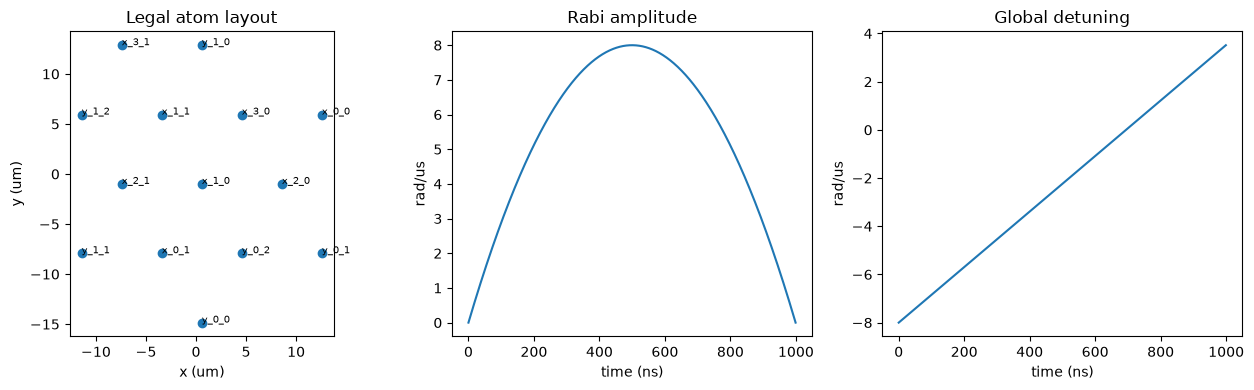

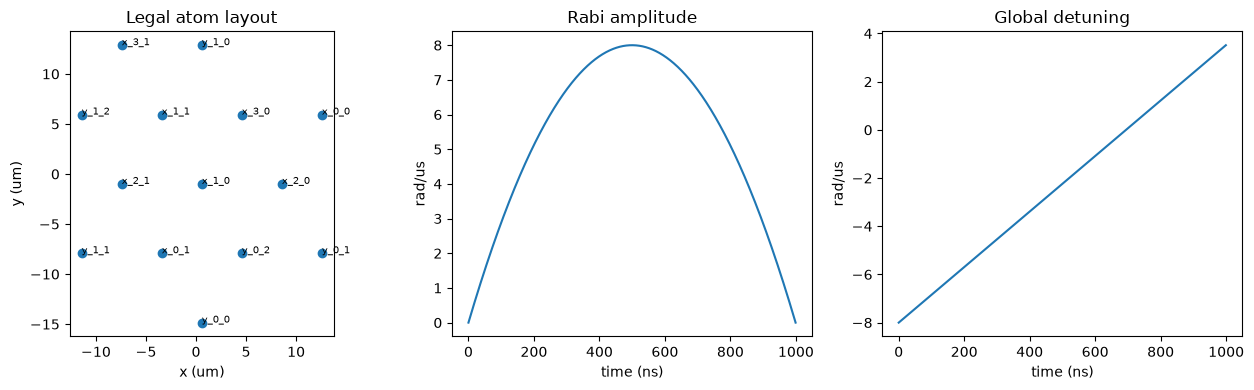

In [14]:
display(pd.DataFrame(json.loads((output / "instances.json").read_text()))[
    ["tier", "instance_seed", "demands", "rho", "largest_demand_ratio", "certificate_valid"]])
display(results[["instance_id", "method", "atom_count", "pair_relative_error",
                 "linear_relative_error", "model_hit_probability_0.1pct"]])
plot_evidence(output, instances[0].id, seed)

## 6. Compare methods and write the four-page report

Exact constrained search repeats one deterministic answer; the other
methods use raw samples. Keep reference, clustering, embedding, emulation
and routing times separate. This is a quality comparison, not a speedup test.

In [15]:
display(results.groupby(["method", "status"], dropna=False).agg(
    instances=("instance_id", "count"), mean_feasibility=("feasibility_rate", "mean"),
    mean_model_gap=("best_model_gap", "mean")))
display(results[["instance_id", "method", "clustering_seconds", "embedding_seconds",
                 "emulation_seconds", "routing_seconds", "reference_seconds"]])
print("Checkpoint:", json.loads((output / "checkpoint.json").read_text()))
write_report(output, rows)
print("Saved:", output / "results.csv", output / "report.pdf")

,,instances,mean_feasibility,mean_model_gap
method,status,,,
classical-constrained,completed,10,1.000000,0.000000
classical-qubo-sa,completed,10,0.211328,0.000000
quantum-global,completed,10,0.022656,0.376642
random-bits,completed,10,0.046094,0.000000


,instance_id,method,clustering_seconds,embedding_seconds,emulation_seconds,routing_seconds,reference_seconds
0,s-0,classical-constrained,0.000340,NaN,NaN,0.000042,0.000497
1,s-0,classical-qubo-sa,0.029044,NaN,NaN,0.000124,0.000497
2,s-0,quantum-global,NaN,0.046552,15.202402,0.000055,0.000497
3,s-0,random-bits,0.001459,NaN,NaN,0.000077,0.000497
4,s-1,classical-constrained,0.000234,NaN,NaN,0.000020,0.000533
5,s-1,classical-qubo-sa,0.028050,NaN,NaN,0.000087,0.000533
6,s-1,quantum-global,NaN,0.047282,12.234884,0.000247,0.000533
7,s-1,random-bits,0.001279,NaN,NaN,0.000073,0.000533
8,s-2,classical-constrained,0.000430,NaN,NaN,0.000024,0.000500
9,s-2,classical-qubo-sa,0.027371,NaN,NaN,0.000101,0.000500


Checkpoint: {'s_passed': True, 'instance_ids': ['s-0', 's-1', 's-2', 's-3', 's-4', 's-5', 's-6', 's-7', 's-8', 's-9'], 'requirements': 'exact QUBO, legal device, feasible raw S shots'}


Saved: /workspaces/duquantum_hack_2026/track_a/outputs/all_demands/results.csv /workspaces/duquantum_hack_2026/track_a/outputs/all_demands/report.pdf


## What did not work / remaining work

Dense slack couplings and unequal linear terms cannot generally be matched
exactly by a 2D array with global detuning. Inspect both embedding errors.
Keep poor feasibility and failures visible; never invent gaps or repair shots.

This run covers all supplied S demand vectors (currently ten), one shared
geometry, sampling seed 0 and two pulse candidates calibrated on `s-0`.
Track A's **seed-based instance generator (A2)** remains a submission gap.
There is no variable reduction, noise/convergence study, M/L, DMM or QPU experiment.

**AI disclosure:** an AI assistant using Copilot SDK in VS Code helped with
code, explanations and report generation. Results are actual local outputs
and require human review. See [MODEL.md](docs/MODEL.md) for full derivations.